<a href="https://colab.research.google.com/github/faishal1900-droid/Python-project-Semester-1/blob/main/Untitled5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Note: '25_water_consumption.csv' not found. Generating sample dataset...

TASK 1: LOAD & INSPECT DATASET
Dataset Dimensions (Rows, Columns): (203, 6)

Column Names & Data Types:
Meter_Record_ID        object
Household_ID           object
Household_Type         object
Zone                   object
Reading_Date           object
Water_Usage_Liters    float64
dtype: object

First 5 Rows:
  Meter_Record_ID Household_ID     Household_Type        Zone Reading_Date  \
0        REC_1001       HH_015             Duplex   West Zone   2025-07-09   
1        REC_1002       HH_019             Duplex  North Zone   2025-05-15   
2        REC_1003       HH_004          Apartment  North Zone   2025-03-30   
3        REC_1004       HH_007              Villa   East Zone   2025-06-21   
4        REC_1005       HH_014  Independent House  South Zone   2025-03-22   

   Water_Usage_Liters  
0                 NaN  
1              236.29  
2              359.90  
3                 NaN  
4              573.38  


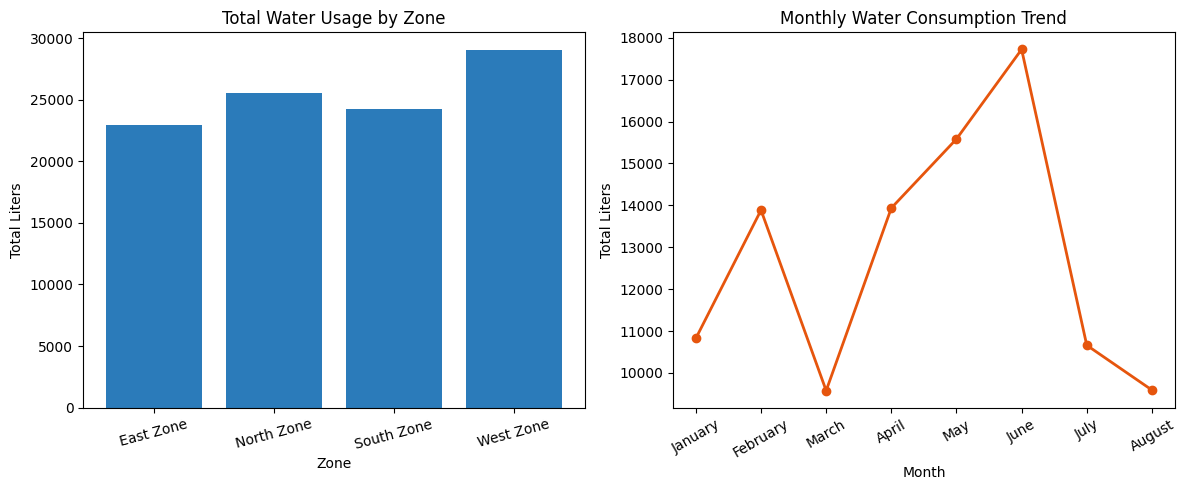

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# ==============================================================================
# HELPER: Auto-generate sample dataset if '25_water_consumption.csv' is missing
# ==============================================================================
file_name = "25_water_consumption.csv"

if not os.path.exists(file_name):
    print(f"Note: '{file_name}' not found. Generating sample dataset...\n")
    np.random.seed(42)
    n_rows = 200
    households = [f"HH_{i:03d}" for i in range(1, 26)]
    hh_types = ["Apartment", "Independent House", "Villa", "Duplex"]
    zones = ["North Zone", "South Zone", "East Zone", "West Zone"]

    hh_meta = {
        hh: (np.random.choice(hh_types), np.random.choice(zones))
        for hh in households
    }

    records = []
    dates = pd.date_range(start="2025-01-01", end="2025-08-31", freq="D")
    for i in range(1, n_rows + 1):
        hh = np.random.choice(households)
        h_type, zone = hh_meta[hh]
        date = np.random.choice(dates)
        usage = round(np.random.normal(loc=450, scale=150), 2)
        if np.random.rand() < 0.05:
            usage = round(np.random.uniform(1100, 1600), 2)
        if np.random.rand() < 0.06:
            usage = np.nan

        records.append({
            "Meter_Record_ID": f"REC_{1000 + i}",
            "Household_ID": hh,
            "Household_Type": h_type,
            "Zone": zone,
            "Reading_Date": pd.to_datetime(date).strftime("%Y-%m-%d"),
            "Water_Usage_Liters": max(50, usage) if not np.isnan(usage) else np.nan
        })

    sample_df = pd.DataFrame(records)
    sample_df = pd.concat([sample_df, sample_df.iloc[:3]], ignore_index=True)
    sample_df.to_csv(file_name, index=False)

# ==============================================================================
# TASK 1: Load the water consumption CSV and inspect dimensions, columns & types
# ==============================================================================
print("=" * 70)
print("TASK 1: LOAD & INSPECT DATASET")
print("=" * 70)
df = pd.read_csv(file_name)
print(f"Dataset Dimensions (Rows, Columns): {df.shape}")
print("\nColumn Names & Data Types:")
print(df.dtypes)
print("\nFirst 5 Rows:")
print(df.head())

# ==============================================================================
# TASK 2: Identify missing values and duplicate Meter_Record_ID entries
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 2: MISSING VALUES & DUPLICATE RECORDS")
print("=" * 70)
print("Missing Values per Column:")
print(df.isnull().sum())

duplicate_count = df.duplicated(subset=["Meter_Record_ID"]).sum()
print(f"\nDuplicate 'Meter_Record_ID' entries found: {duplicate_count}")
if duplicate_count > 0:
    df = df.drop_duplicates(subset=["Meter_Record_ID"]).reset_index(drop=True)
    print(f"Duplicates removed. Updated row count: {len(df)}")

# ==============================================================================
# TASK 3: Handle missing Water_Usage_Liters values and explain chosen method
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 3: HANDLING MISSING WATER USAGE VALUES")
print("=" * 70)
df["Water_Usage_Liters"] = df["Water_Usage_Liters"].fillna(
    df.groupby("Household_Type")["Water_Usage_Liters"].transform("median")
)
df["Water_Usage_Liters"] = df["Water_Usage_Liters"].fillna(df["Water_Usage_Liters"].median())

print("Method Used: Group-wise Median Imputation (by Household_Type).")
print("Reason: Median avoids distortion from extreme high-usage outliers.")
print(f"Remaining missing values: {df['Water_Usage_Liters'].isnull().sum()}")

# ==============================================================================
# TASK 4: Convert Reading_Date to datetime and extract month and weekday
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 4: DATETIME CONVERSION & FEATURE EXTRACTION")
print("=" * 70)
df["Reading_Date"] = pd.to_datetime(df["Reading_Date"])
df["Month_Num"] = df["Reading_Date"].dt.month
df["Month"] = df["Reading_Date"].dt.month_name()
df["Weekday"] = df["Reading_Date"].dt.day_name()
print(df[["Reading_Date", "Month", "Weekday"]].head())

# ==============================================================================
# TASK 5: Calculate total water consumption and average consumption per household
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 5: TOTAL & AVERAGE CONSUMPTION PER HOUSEHOLD")
print("=" * 70)
household_summary = df.groupby("Household_ID")["Water_Usage_Liters"].agg(
    Total_Consumption_Liters="sum",
    Average_Consumption_Liters="mean"
).round(2)
print(household_summary.head(10))

# ==============================================================================
# TASK 6: Calculate month-to-month consumption change for each household
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 6: MONTH-TO-MONTH CONSUMPTION CHANGE PER HOUSEHOLD")
print("=" * 70)
monthly_hh = (
    df.groupby(["Household_ID", "Month_Num", "Month"])["Water_Usage_Liters"]
    .sum()
    .reset_index()
    .sort_values(["Household_ID", "Month_Num"])
)
monthly_hh["Prev_Month_Usage"] = monthly_hh.groupby("Household_ID")["Water_Usage_Liters"].shift(1)
monthly_hh["MoM_Change_Liters"] = (monthly_hh["Water_Usage_Liters"] - monthly_hh["Prev_Month_Usage"]).round(2)
monthly_hh["MoM_Change_%"] = ((monthly_hh["MoM_Change_Liters"] / monthly_hh["Prev_Month_Usage"]) * 100).round(2)
print(monthly_hh[["Household_ID", "Month", "Water_Usage_Liters", "MoM_Change_Liters", "MoM_Change_%"]].head(10))

# ==============================================================================
# TASK 7: Rank household types by total water usage
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 7: RANK HOUSEHOLD TYPES BY TOTAL WATER USAGE")
print("=" * 70)
hh_type_rank = (
    df.groupby("Household_Type")["Water_Usage_Liters"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
hh_type_rank["Rank"] = hh_type_rank["Water_Usage_Liters"].rank(ascending=False).astype(int)
print(hh_type_rank)

# ==============================================================================
# TASK 8: Compare average water consumption across building types or zones
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 8: AVERAGE WATER CONSUMPTION ACROSS ZONES & HOUSEHOLD TYPES")
print("=" * 70)
zone_type_comparison = df.pivot_table(
    values="Water_Usage_Liters",
    index="Zone",
    columns="Household_Type",
    aggfunc="mean"
).round(2)
print(zone_type_comparison)

# ==============================================================================
# TASK 9: Identify the 10 households with the highest total water consumption
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 9: TOP 10 HOUSEHOLDS WITH HIGHEST TOTAL CONSUMPTION")
print("=" * 70)
top_10_households = household_summary.sort_values(by="Total_Consumption_Liters", ascending=False).head(10)
print(top_10_households)

# ==============================================================================
# TASK 10: Find the month with the highest overall water usage
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 10: MONTH WITH HIGHEST OVERALL WATER USAGE")
print("=" * 70)
monthly_overall = df.groupby(["Month_Num", "Month"])["Water_Usage_Liters"].sum().reset_index()
monthly_overall = monthly_overall.sort_values("Month_Num")
highest_month_row = monthly_overall.loc[monthly_overall["Water_Usage_Liters"].idxmax()]
print(monthly_overall[["Month", "Water_Usage_Liters"]])
print(f"\nHighest Usage Month: {highest_month_row['Month']} ({highest_month_row['Water_Usage_Liters']:.2f} Liters)")

# ==============================================================================
# TASK 11: Use a dictionary for zone-wise totals and a set for unique zones
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 11: DICTIONARY FOR ZONE TOTALS & SET FOR UNIQUE ZONES")
print("=" * 70)
unique_zones = set(df["Zone"].dropna())
zone_totals_dict = df.groupby("Zone")["Water_Usage_Liters"].sum().round(2).to_dict()

print(f"Unique Zones (Set): {unique_zones}")
print("Zone-wise Consumption Totals (Dictionary):")
for zone, total in zone_totals_dict.items():
    print(f"  - {zone}: {total} Liters")

# ==============================================================================
# TASK 12: Function to classify consumption as Low, Normal, or High
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 12: CONSUMPTION CLASSIFICATION (LOW / NORMAL / HIGH)")
print("=" * 70)
def classify_consumption(liters):
    if liters < 350:
        return "Low"
    elif liters <= 600:
        return "Normal"
    else:
        return "High"

df["Consumption_Category"] = df["Water_Usage_Liters"].apply(classify_consumption)
print("Consumption Category Distribution:")
print(df["Consumption_Category"].value_counts())

# ==============================================================================
# TASK 13: Use NumPy to calculate mean, median, variance, and std deviation
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 13: NUMPY STATISTICAL SUMMARY")
print("=" * 70)
usage_array = df["Water_Usage_Liters"].to_numpy()
mean_val = np.mean(usage_array)
median_val = np.median(usage_array)
variance_val = np.var(usage_array)
std_val = np.std(usage_array)

print("Mean Usage:", round(mean_val, 2), "Liters")
print("Median Usage:", round(median_val, 2), "Liters")
print("Variance:", round(variance_val, 2))
print("Standard Deviation:", round(std_val, 2), "Liters")

# ==============================================================================
# TASK 14: Identify unusually high consumption records using IQR method
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 14: OUTLIER DETECTION (IQR METHOD) & HOUSEHOLD TYPE COMPARISON")
print("=" * 70)
Q1 = np.percentile(usage_array, 25)
Q3 = np.percentile(usage_array, 75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

high_outliers = df[df["Water_Usage_Liters"] > upper_bound]
print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Upper Outlier Threshold: {upper_bound:.2f} Liters")
print(f"Unusually High Consumption Records Found: {len(high_outliers)}")
if not high_outliers.empty:
    print(high_outliers[["Meter_Record_ID", "Household_ID", "Household_Type", "Zone", "Water_Usage_Liters"]].head())

print("\nAverage Usage Across Household Types:")
print(df.groupby("Household_Type")["Water_Usage_Liters"].mean().round(2))

# ==============================================================================
# TASK 15: Create a WaterMeter class & print 5 conservation recommendations
# ==============================================================================
print("\n" + "=" * 70)
print("TASK 15: WATERMETER CLASS & CONSERVATION RECOMMENDATIONS")
print("=" * 70)

class WaterMeter:
    def __init__(self, meter_id, household_type):
        self.meter_id = meter_id
        self.household_type = household_type

    def display_info(self):
        return f"Meter ID: {self.meter_id} | Household Type: {self.household_type}"

sample_meter = WaterMeter(df.loc[0, "Meter_Record_ID"], df.loc[0, "Household_Type"])
print("Sample WaterMeter Object ->", sample_meter.display_info())

recommendations = [
    "1. Install Smart Leak Alerts: High outlier readings (> Q3 + 1.5*IQR) indicate potential pipe leaks or overflowing tanks; automated alerts can prevent sudden spikes.",
    "2. Target High-Usage Household Categories: Focus conservation audits and subsidized low-flow fixtures on top-consuming household types (e.g., Villas/Independent Houses).",
    "3. Peak-Month Usage Caps: Introduce tiered water tariffs during peak consumption months to discourage non-essential outdoor watering and car washing.",
    "4. Zone-Level Pressure Management: Optimize water supply pressure in high-consumption zones to reduce background leakage and excessive flow rates.",
    "5. Rainwater Harvesting & Greywater Reuse: Mandate rainwater harvesting systems and greywater recycling for landscaping in top-consuming households."
]

print("\nFive Data-Driven Water Conservation Recommendations:")
for rec in recommendations:
    print(rec)

# ==============================================================================
# BONUS VISUALIZATION: Display & Save Summary Charts
# ==============================================================================
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.bar(zone_totals_dict.keys(), zone_totals_dict.values(), color="#2b7bba")
plt.title("Total Water Usage by Zone")
plt.xlabel("Zone")
plt.ylabel("Total Liters")
plt.xticks(rotation=15)

plt.subplot(1, 2, 2)
plt.plot(monthly_overall["Month"], monthly_overall["Water_Usage_Liters"], marker="o", color="#e6550d", linewidth=2)
plt.title("Monthly Water Consumption Trend")
plt.xlabel("Month")
plt.ylabel("Total Liters")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("water_usage_analysis_charts.png", dpi=150)
plt.show()